# H100 2장 병렬화 실습 분석

`results/<ID>/`에 모인 측정 결과를 표와 그래프로 비교. 실습 방법은 [README.md](../README.md), 기록은 [RESULTS.md](RESULTS.md).

| 절 | 답하는 질문 |
| --- | --- |
| 1. 측정 결과 표 | 구성, 시나리오, 동시 요청 수별 처리량과 지연, 실패한 요청 수 |
| 2. KV 캐시 토큰 수 | 구성별로 KV 캐시에 담을 수 있는 토큰 수, 측정 지표가 아니라 TTFT가 튈 때 원인 확인용 |
| 3. 동시 요청 수별 그래프 | 동시 요청이 늘 때 출력 처리량, TTFT, ITL의 변화 |
| 4. 예상 결과 | README 4.2절에서 4.4절의 예상 결과가 맞았는지 확인 |

- `experiments/` 폴더에서 실행 (`RESULTS_DIR = Path("results")`)
- 필요한 패키지는 `pandas`, `matplotlib`
- 그래프 글자는 서버에 한글 글꼴이 없어도 깨지지 않게 영어로 표시

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import NullLocator

RESULTS_DIR = Path("results")

# ID prefix -> (table label, ASCII plot title)
EXPERIMENTS = {
    "14b": ("실험 1: Qwen3-14B", "Exp 1: Qwen3-14B (fits 1 GPU)"),
    "72b": ("실험 2: Qwen2.5-72B-Instruct", "Exp 2: Qwen2.5-72B-Instruct (needs 2 GPUs)"),
    "moe": ("실험 3: Qwen3-30B-A3B", "Exp 3: Qwen3-30B-A3B (MoE)"),
}
COLUMNS = [
    "id", "experiment", "model", "gpus", "input_len", "output_len", "concurrency",
    "output_throughput", "median_ttft_ms", "p99_ttft_ms", "median_itl_ms", "p99_itl_ms",
    "completed", "failed",
]
RESULT_KEYS = [
    "output_throughput", "median_ttft_ms", "p99_ttft_ms", "median_itl_ms", "p99_itl_ms",
    "completed", "failed",
]
RESULT_FILE = re.compile(r"in(\d+)_out(\d+)_c(\d+)\.json")


def prefix(run_id):
    return run_id.split("-")[0]


runs = {path.parent: json.loads(path.read_text()) for path in RESULTS_DIR.glob("*/meta.json")}
runs = dict(sorted(runs.items(), key=lambda item: (prefix(item[1]["id"]), item[1]["gpus"], item[1]["id"])))


def config_order(exp_prefix):
    return [meta["id"] for meta in runs.values() if prefix(meta["id"]) == exp_prefix]

## 1. 측정 결과 표

- `vllm bench serve` 결과 JSON 하나가 한 행, 입력 길이, 출력 길이, 동시 요청 수는 파일 이름에서 읽음
- `failed`가 모두 0인지 확인
- `summary`는 동시 요청 수를 열로 펼친 표로, `RESULTS.md`에 숫자를 옮길 때 사용

In [2]:
rows = []
for run_dir, meta in runs.items():
    for path in sorted(run_dir.glob("in*_out*_c*.json")):
        match = RESULT_FILE.fullmatch(path.name)
        if match is None:
            continue
        input_len, output_len, concurrency = map(int, match.groups())
        result = json.loads(path.read_text())
        rows.append({
            "id": meta["id"],
            "experiment": EXPERIMENTS[prefix(meta["id"])][0],
            "model": meta["model"],
            "gpus": meta["gpus"],
            "input_len": input_len,
            "output_len": output_len,
            "concurrency": concurrency,
            **{key: result.get(key, float("nan")) for key in RESULT_KEYS},
        })

df = pd.DataFrame(rows).reindex(columns=COLUMNS)
df = df.sort_values(["experiment", "input_len", "gpus", "id", "concurrency"], ignore_index=True)
print(f"{len(runs)} configs, {len(df)} results, shape {df.shape}")
df

8 configs, 30 results, shape (30, 14)


,id,experiment,model,gpus,input_len,output_len,concurrency,output_throughput,median_ttft_ms,p99_ttft_ms,median_itl_ms,p99_itl_ms,completed,failed
0,14b-1gpu,실험 1: Qwen3-14B,Qwen/Qwen3-14B,1,1024,256,1,87.026267,71.622177,74.476970,11.264464,12.544826,32,0
1,14b-1gpu,실험 1: Qwen3-14B,Qwen/Qwen3-14B,1,1024,256,8,604.237019,351.174115,378.309519,11.876774,13.839981,32,0
2,14b-1gpu,실험 1: Qwen3-14B,Qwen/Qwen3-14B,1,1024,256,32,1680.111073,1063.973846,1453.899092,13.691051,18.047068,128,0
3,14b-1gpu,실험 1: Qwen3-14B,Qwen/Qwen3-14B,1,1024,256,128,3039.914350,1403.683252,5582.046072,20.896942,351.786869,512,0
4,14b-dp2,실험 1: Qwen3-14B,Qwen/Qwen3-14B,2,1024,256,1,87.387733,62.701730,71.444591,11.239390,12.196564,32,0
5,14b-dp2,실험 1: Qwen3-14B,Qwen/Qwen3-14B,2,1024,256,8,654.746074,179.908354,205.450752,11.521861,12.457443,32,0
6,14b-dp2,실험 1: Qwen3-14B,Qwen/Qwen3-14B,2,1024,256,32,2135.396175,472.547390,732.286498,12.328640,14.585775,128,0
7,14b-dp2,실험 1: Qwen3-14B,Qwen/Qwen3-14B,2,1024,256,128,4755.516625,1127.966925,2846.204250,16.101446,341.260076,512,0
8,14b-pp2,실험 1: Qwen3-14B,Qwen/Qwen3-14B,2,1024,256,1,87.019477,59.752284,63.115242,11.289260,12.636143,32,0
9,14b-pp2,실험 1: Qwen3-14B,Qwen/Qwen3-14B,2,1024,256,8,584.819707,348.354347,372.475358,12.351117,12.691689,32,0


In [3]:
summary = df.pivot_table(
    index=["experiment", "input_len", "output_len", "id"],
    columns="concurrency",
    values=["output_throughput", "median_ttft_ms", "median_itl_ms"],
).round(1)
summary

median_itl_ms        \
concurrency                                                        1     8     
experiment                 input_len output_len id                             
실험 1: Qwen3-14B            1024      256        14b-1gpu          11.3  11.9   
                                                14b-dp2           11.2  11.5   
                                                14b-pp2           11.3  12.4   
                                                14b-tp2            6.9   7.2   
실험 2: Qwen2.5-72B-Instruct 1024      256        72b-pp2           49.9  51.7   
                                                72b-tp2           27.7  28.4   
실험 3: Qwen3-30B-A3B        1024      256        moe-ep2            5.7   8.2   
                                                moe-tp2            4.0   6.7   

                                                                            \
concurrency                                                16    32    128   
experiment                 input_len output_len id                           
실험 1: Qwen3-14B            1024      256        14b-1gpu   NaN  13.7  20.9   
                                                14b-dp2    NaN  12.3  16.1   
                                                14b-pp2    NaN  13.4  17.1   
                                                14b-tp2    NaN   8.4  12.6   
실험 2: Qwen2.5-72B-Instruct 1024      256        72b-pp2   51.6   NaN   NaN   
                                                72b-tp2   29.0   NaN   NaN   
실험 3: Qwen3-30B-A3B        1024      256        moe-ep2    NaN  11.0  16.5   
                                                moe-tp2    NaN   9.9  15.1   

                                                         median_ttft_ms  \
concurrency                                                         1     
experiment                 input_len output_len id                        
실험 1: Qwen3-14B            1024      256        14b-1gpu           71.6   
                                                14b-dp2            62.7   
                                                14b-pp2            59.8   
                                                14b-tp2            42.6   
실험 2: Qwen2.5-72B-Instruct 1024      256        72b-pp2           223.9   
                                                72b-tp2           143.5   
실험 3: Qwen3-30B-A3B        1024      256        moe-ep2           107.3   
                                                moe-tp2            65.1   

                                                                           \
concurrency                                                  8        16    
experiment                 input_len output_len id                          
실험 1: Qwen3-14B            1024      256        14b-1gpu   351.2      NaN   
                                                14b-dp2    179.9      NaN   
                                                14b-pp2    348.4      NaN   
                                                14b-tp2    211.2      NaN   
실험 2: Qwen2.5-72B-Instruct 1024      256        72b-pp2   1566.3  17023.7   
                                                72b-tp2   1008.1   1481.1   
실험 3: Qwen3-30B-A3B        1024      256        moe-ep2    165.6      NaN   
                                                moe-tp2    138.1      NaN   

                                                                          \
concurrency                                                  32      128   
experiment                 input_len output_len id                         
실험 1: Qwen3-14B            1024      256        14b-1gpu  1064.0  1403.7   
                                                14b-dp2    472.5  1128.0   
                                                14b-pp2    759.2  1094.3   
                                                14b-tp2    559.5   853.9   
실험 2: Qwen2.5-72B-Instruct 1024      256        72b-pp2      NaN     NaN   
                                   

## 2. KV 캐시 토큰 수

- 측정 지표는 아니고, KV 캐시 토큰 수가 동시 요청 수 × 1280(입력 + 출력)보다 작으면 요청이 대기열에서 기다려 TTFT가 튐
- 서버 시작 로그에서 뽑은 `kv.txt`의 `KV cache size` 줄을 엔진마다 하나씩 읽음
- `14b-dp2`와 `moe-ep2`는 엔진이 2개라 값도 2개, `kv_tokens_total`은 엔진 값의 합
- `max_concurrency_8192`는 8192 토큰짜리 요청을 동시에 몇 개 담을 수 있는지에 대한 vLLM의 계산
- 구성마다 가중치를 뺀 나머지 메모리가 KV 캐시, `kv.txt`의 `Model loading took`, `Available KV cache memory` 줄로 확인

In [4]:
KV_TOKENS = re.compile(r"KV cache size: ([\d,]+) tokens")
MAX_CONCURRENCY = re.compile(r"Maximum concurrency for [\d,]+ tokens per request: ([\d.]+)x")

kv_rows = []
for run_dir, meta in runs.items():
    kv_file = run_dir / "kv.txt"
    text = kv_file.read_text() if kv_file.exists() else ""
    tokens = [int(value.replace(",", "")) for value in KV_TOKENS.findall(text)]
    kv_rows.append({
        "id": meta["id"],
        "gpus": meta["gpus"],
        "engines": len(tokens),
        "kv_tokens_per_engine": tokens,
        "kv_tokens_total": sum(tokens) if tokens else None,
        "max_concurrency_8192": [float(value) for value in MAX_CONCURRENCY.findall(text)],
    })

kv = pd.DataFrame(kv_rows)
kv

,id,gpus,engines,kv_tokens_per_engine,kv_tokens_total,max_concurrency_8192
0,14b-1gpu,1,1,[262144],262144,[32.0]
1,14b-dp2,2,2,"[262144, 262144]",524288,"[32.0, 32.0]"
2,14b-pp2,2,1,[691200],691200,[84.38]
3,14b-tp2,2,1,[698368],698368,[85.25]
4,72b-pp2,2,1,[11264],11264,[1.38]
5,72b-tp2,2,1,[18432],18432,[2.25]
6,moe-ep2,2,2,"[397312, 397312]",794624,"[48.5, 48.5]"
7,moe-tp2,2,1,[833536],833536,[101.75]


## 3. 동시 요청 수별 처리량과 지연

- 실험마다 그래프 한 줄, 왼쪽부터 출력 처리량, TTFT 중앙값, ITL 중앙값
- 가로축은 동시 요청 수 (1, 8, 32, 128), TTFT 세로축은 로그 눈금
- KV 캐시가 모자란 구성은 동시 요청이 늘면 요청이 대기열에서 기다려 TTFT가 급격히 증가

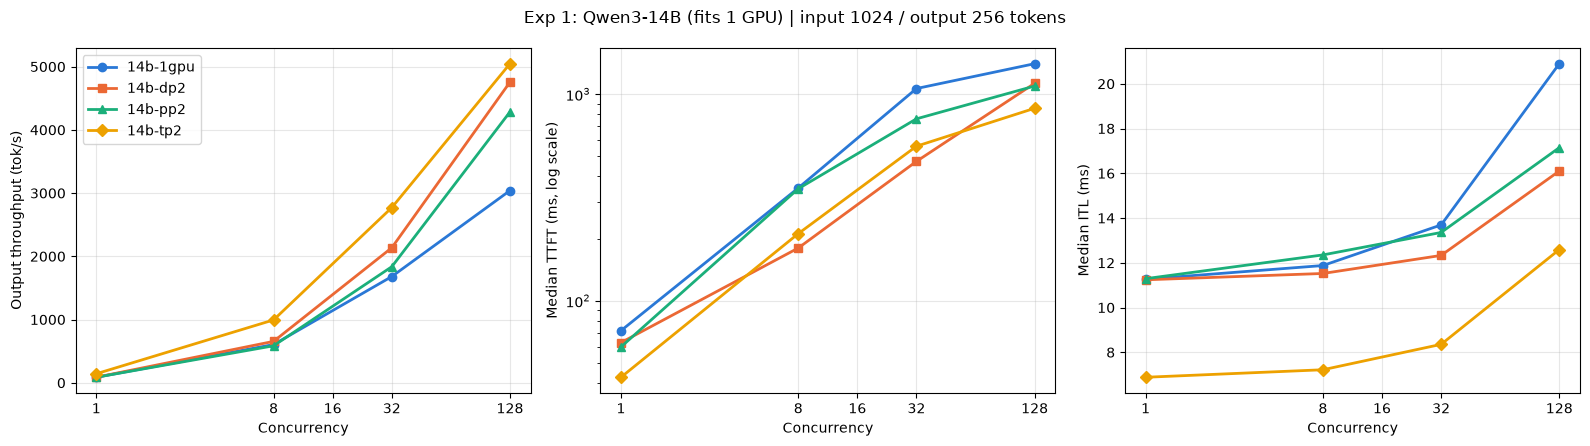

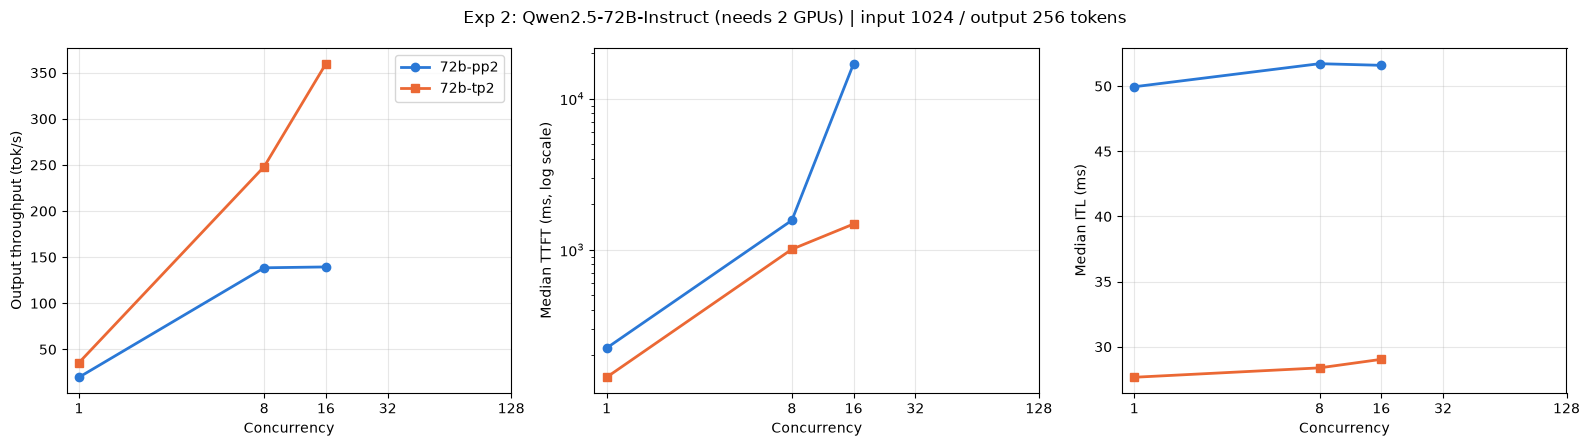

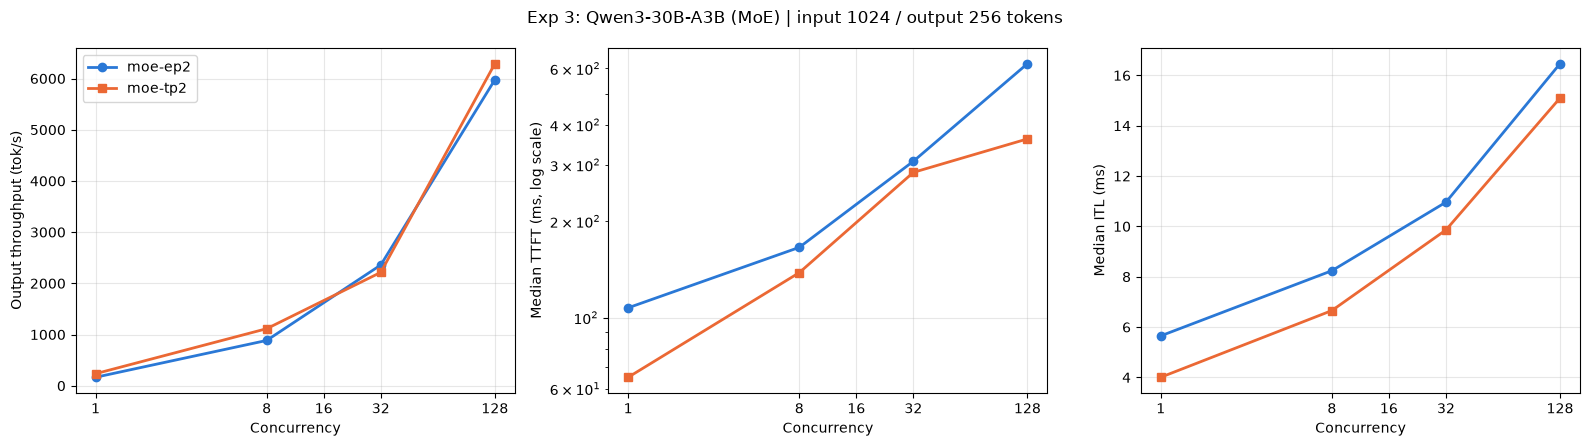

In [5]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
STYLE = {}
for exp_prefix in EXPERIMENTS:
    for i, run_id in enumerate(config_order(exp_prefix)):
        STYLE[run_id] = {"color": COLORS[i], "marker": MARKERS[i]}

PANELS = [
    ("output_throughput", "Output throughput (tok/s)", "linear"),
    ("median_ttft_ms", "Median TTFT (ms, log scale)", "log"),
    ("median_itl_ms", "Median ITL (ms)", "linear"),
]
concurrencies = sorted(df["concurrency"].unique())

for exp_prefix, (_, title) in EXPERIMENTS.items():
    exp = df[df["id"].map(prefix) == exp_prefix]
    for (input_len, output_len), scenario in exp.groupby(["input_len", "output_len"]):
        fig, axes = plt.subplots(1, len(PANELS), figsize=(16, 4.5))
        for ax, (column, label, yscale) in zip(axes, PANELS):
            for run_id in config_order(exp_prefix):
                run = scenario[scenario["id"] == run_id].sort_values("concurrency")
                if not run.empty:
                    ax.plot(run["concurrency"], run[column], label=run_id, linewidth=2, markersize=6, **STYLE[run_id])
            ax.set_xscale("log", base=2)
            ax.set_xticks(concurrencies, [str(c) for c in concurrencies])
            ax.xaxis.set_minor_locator(NullLocator())
            ax.set_yscale(yscale)
            ax.set_xlabel("Concurrency")
            ax.set_ylabel(label)
            ax.grid(alpha=0.3)
        axes[0].legend()
        fig.suptitle(f"{title} | input {input_len} / output {output_len} tokens")
        fig.tight_layout()
        plt.show()

## 4. 예상 결과

README 4.2절에서 4.4절의 예상 결과가 맞았는지 확인. ITL은 동시 요청 1, 출력 처리량은 동시 요청 128 기준이고, ITL은 짧을수록 빠름.

### 4.1. 실험 1. 1장으로 서빙할 수 있는 모델 (Qwen3-14B)

- [x] `14b-dp2`: 출력 처리량이 1장보다 높음 (4755.5 vs 3039.9 tok/s)
- [x] `14b-tp2`: ITL이 1장보다 빠름 (6.9 vs 11.3 ms)
- [x] `14b-pp2`: 출력 처리량이 1장보다 높음 (4284.5 vs 3039.9 tok/s)

### 4.2. 실험 2. 2장으로 서빙해야 하는 모델 (Qwen2.5-72B-Instruct)

- [x] `72b-tp2`: ITL이 PP보다 빠름 (27.7 vs 50.0 ms)
- [x] `72b-pp2`: ITL이 TP보다 느림 (50.0 vs 27.7 ms)

### 4.3. 실험 3. MoE 모델 (Qwen3-30B-A3B)

- [ ] `moe-ep2`: 출력 처리량이 TP보다 높음 (5975.8 vs 6290.2 tok/s), 예상과 다름, 이유는 `RESULTS.md` 4절